In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(160)

DATA = Path("..")
FIGS = Path("figures")
FIGS.mkdir(exist_ok=True)

INK = "#1f2933"
MUTED = "#52616b"
ALL_ELSE = "#d95f02"
USA_CAN = "#2678b2"
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a959e",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e4e8eb",
    "text.color": INK,
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
})

eiu = pl.read_csv(DATA / "democracy-index-eiu.csv")
print(f"Loaded {eiu.height:,} raw EIU rows across {eiu['Year'].min()}–{eiu['Year'].max()}.")

Loaded 2,765 raw EIU rows across 2006–2023.


# North America democracy-score change, 2006–2022

## Claim

Across this transparent North American comparison, the 12 selected countries in `all_else` had a steeper average EIU democracy-score decline from 2006 to 2022 than Canada and the United States (`usa_can`). This is descriptive evidence about changes in the EIU measure, not a causal account of why they occurred.

# Approach / Thoughts

Angle I want to take here is to try to come up with a finding about what the EIU decline really means and what factors may explain the variation over time. 
Note that EIU decline means democracy decline.

Idea is to try to find the ones who have significant decline and then try to get some context on what was happening during the periods they were in decline.
Then maybe we can look and see if there are any other sources that provide data on those extra dimensions we have identified as potentially influencing and affecting the EIU score.
Potential pipeline:
```mermaid
flowchart TD
    A["Identify who had the biggest declines across regions (largest decline appears to be North America)"]
    B["Identify the top 3–5 countries with the biggest individual declines over the time window"]
    C["Ask: What was going on there?"]
    D["Identify potential explanatory factors related to the negative score delta in each country (e.g., revolutions, political change, inflation, issues in neighboring countries, immigration, economic difficulty, etc.)"]
    E["Use available data to add context"]
    F["Optional: do EDA if enough relevant data exists"]
    G["Combine score-change data and contextual data"]
    H["Develop a preliminary finding"]

    A --> B
    B --> C
    C --> D
    D --> E
    E --> F
    F --> G
    G --> H

    A -.->|Refine country selection| B
```

# P1: Who had the biggest declines?

This section is to find who had the biggest declines, which corresponds to everything up to the "why" part of the flowchart.

## Transparent geography and endpoint design

OWID's **North America** geographic definition includes Northern America, Central America, and Caribbean countries. The code below records the relevant ISO-3 code set explicitly, then retains only the 14 pre-specified comparison countries in two groups: `usa_can` (Canada and the United States) and `all_else` (Costa Rica, Cuba, Dominican Republic, El Salvador, Guatemala, Haiti, Honduras, Jamaica, Mexico, Nicaragua, Panama, and Trinidad and Tobago). These are transparent analysis labels for the selected countries; they are not exhaustive geographic classifications.

The primary comparison is the endpoint difference, 2022 score minus 2006 score. The panel has no 2007 or 2009 observations, so the two endpoint and 2006–2014 / 2014–2022 comparisons are not interpreted as adjacent annual changes.

In [10]:
def build_country_split(eiu: pl.DataFrame) -> pl.DataFrame:
    """Validate, subset, and reshape the pre-specified North America comparison."""
    required = {"Entity", "Code", "Year", "Democracy score"}
    missing = required - set(eiu.columns)
    assert not missing, f"Missing required columns: {sorted(missing)}"

    # OWID's geographic North America includes Northern America, Central America,
    # and the Caribbean. This full set is kept visible before selecting the study groups.
    owid_north_america_codes = {
        "ATG", "BHS", "BRB", "BZE", "CAN", "CRI", "CUB", "DMA", "DOM", "GRD",
        "GTM", "HTI", "HND", "JAM", "KNA", "LCA", "MEX", "NIC", "PAN", "SLV",
        "TTO", "USA", "VCT",
    }
    groups = {
        "usa_can": {"CAN", "USA"},
        "all_else": {"CRI", "CUB", "DOM", "SLV", "GTM", "HTI", "HND", "JAM", "MEX", "NIC", "PAN", "TTO"},
    }
    expected_codes = set().union(*groups.values())
    assert expected_codes <= owid_north_america_codes

    country_rows = eiu.filter(
        pl.col("Code").is_not_null()
        & pl.col("Code").str.contains(r"^[A-Z]{3}$")
        & ~pl.col("Code").str.starts_with("OWID_")
    )
    assert country_rows.select(pl.struct("Code", "Year").n_unique()).item() == country_rows.height, "Duplicate country-year rows"
    assert country_rows.select(pl.col("Democracy score").is_between(0, 10, closed="both").all()).item(), "Score outside 0–10"

    north_america = country_rows.filter(pl.col("Code").is_in(sorted(owid_north_america_codes)))
    selected = north_america.filter(pl.col("Code").is_in(sorted(expected_codes)))
    endpoint_counts = selected.filter(pl.col("Year").is_in([2006, 2014, 2022])).group_by("Code").len()
    assert endpoint_counts.height == len(expected_codes) and endpoint_counts.select((pl.col("len") == 3).all()).item(), "Incomplete endpoint records"

    country_split = (
        selected.filter(pl.col("Year").is_in([2006, 2014, 2022]))
        .pivot(on="Year", index=["Entity", "Code"], values="Democracy score")
        .rename({"2006": "score_2006", "2014": "score_2014", "2022": "score_2022"})
        .with_columns(
            pl.when(pl.col("Code").is_in(sorted(groups["usa_can"])))
            .then(pl.lit("usa_can"))
            .otherwise(pl.lit("all_else"))
            .alias("group")
        )
        .with_columns(
            (pl.col("score_2022") - pl.col("score_2006")).alias("delta_06_22"),
            (pl.col("score_2014") - pl.col("score_2006")).alias("delta_06_14"),
            (pl.col("score_2022") - pl.col("score_2014")).alias("delta_14_22"),
        )
        .select("Entity", "Code", "group", "score_2006", "score_2014", "score_2022", "delta_06_22", "delta_06_14", "delta_14_22")
        .sort("group", "Code")
    )
    assert country_split.height == 14 and country_split["Code"].n_unique() == 14
    assert country_split.select(pl.col("group").is_in(["usa_can", "all_else"]).all()).item()
    assert country_split.group_by("Code").len().select((pl.col("len") == 1).all()).item()
    return country_split


country_split = build_country_split(eiu)

In [11]:
country_split = build_country_split(eiu)
country_split.sample(5)

Entity,Code,group,score_2006,score_2014,score_2022,delta_06_22,delta_06_14,delta_14_22
str,str,str,f64,f64,f64,f64,f64,f64
"""Trinidad and Tobago""","""TTO""","""all_else""",7.18,6.99,7.16,-0.02,-0.19,0.17
"""Honduras""","""HND""","""all_else""",6.25,5.84,5.15,-1.1,-0.41,-0.69
"""Guatemala""","""GTM""","""all_else""",6.07,5.81,4.68,-1.39,-0.26,-1.13
"""Dominican Republic""","""DOM""","""all_else""",6.13,6.67,6.39,0.26,0.54,-0.28
"""Nicaragua""","""NIC""","""all_else""",5.68,5.32,2.5,-3.18,-0.36,-2.82


In [12]:
membership_audit = country_split.select("Entity", "Code", "group").sort("group", "Code")
print("Membership audit — all 14 mapped countries appear once:")
print(membership_audit)
print("\nGroup counts:")
print(country_split.group_by("group").len().sort("group"))

Membership audit — all 14 mapped countries appear once:
shape: (14, 3)
┌─────────────────────┬──────┬──────────┐
│ Entity              ┆ Code ┆ group    │
│ ---                 ┆ ---  ┆ ---      │
│ str                 ┆ str  ┆ str      │
╞═════════════════════╪══════╪══════════╡
│ Costa Rica          ┆ CRI  ┆ all_else │
│ Cuba                ┆ CUB  ┆ all_else │
│ Dominican Republic  ┆ DOM  ┆ all_else │
│ Guatemala           ┆ GTM  ┆ all_else │
│ Honduras            ┆ HND  ┆ all_else │
│ Haiti               ┆ HTI  ┆ all_else │
│ Jamaica             ┆ JAM  ┆ all_else │
│ Mexico              ┆ MEX  ┆ all_else │
│ Nicaragua           ┆ NIC  ┆ all_else │
│ Panama              ┆ PAN  ┆ all_else │
│ El Salvador         ┆ SLV  ┆ all_else │
│ Trinidad and Tobago ┆ TTO  ┆ all_else │
│ Canada              ┆ CAN  ┆ usa_can  │
│ United States       ┆ USA  ┆ usa_can  │
└─────────────────────┴──────┴──────────┘

Group counts:
shape: (2, 2)
┌──────────┬─────┐
│ group    ┆ len │
│ ---      ┆ --- │
│ s

## Country-level evidence

The next displays separate endpoint declines, improvements, and any exact zero changes. Together they must exhaust the validated 14-country table.

In [13]:
negative = country_split.filter(pl.col("delta_06_22") < 0).sort("delta_06_22")
positive = country_split.filter(pl.col("delta_06_22") > 0).sort("delta_06_22", descending=True)
zero = country_split.filter(pl.col("delta_06_22") == 0).sort("Entity")

assert negative.height + positive.height + zero.height == country_split.height
print(f"Negative endpoint changes ({negative.height} countries):")
print(negative.select("Entity", "Code", "group", "score_2006", "score_2022", "delta_06_22"))
print(f"\nPositive endpoint changes ({positive.height} countries):")
print(positive.select("Entity", "Code", "group", "score_2006", "score_2022", "delta_06_22"))
print(f"\nZero-change countries ({zero.height}):")
print(zero.select("Entity", "Code", "group", "delta_06_22"))

Negative endpoint changes (12 countries):
shape: (12, 6)
┌─────────────────────┬──────┬──────────┬────────────┬────────────┬─────────────┐
│ Entity              ┆ Code ┆ group    ┆ score_2006 ┆ score_2022 ┆ delta_06_22 │
│ ---                 ┆ ---  ┆ ---      ┆ ---        ┆ ---        ┆ ---         │
│ str                 ┆ str  ┆ str      ┆ f64        ┆ f64        ┆ f64         │
╞═════════════════════╪══════╪══════════╪════════════╪════════════╪═════════════╡
│ Nicaragua           ┆ NIC  ┆ all_else ┆ 5.68       ┆ 2.5        ┆ -3.18       │
│ Mexico              ┆ MEX  ┆ all_else ┆ 6.67       ┆ 5.25       ┆ -1.42       │
│ Guatemala           ┆ GTM  ┆ all_else ┆ 6.07       ┆ 4.68       ┆ -1.39       │
│ Haiti               ┆ HTI  ┆ all_else ┆ 4.19       ┆ 2.81       ┆ -1.38       │
│ El Salvador         ┆ SLV  ┆ all_else ┆ 6.22       ┆ 5.06       ┆ -1.16       │
│ Honduras            ┆ HND  ┆ all_else ┆ 6.25       ┆ 5.15       ┆ -1.1        │
│ Cuba                ┆ CUB  ┆ all_else ┆

## Group summaries, timing, and robustness

Means describe the country-level scores in each deliberately selected group; they are not population-weighted regional estimates. The leave-one-country-out check probes whether the `all_else` result is solely driven by one country.

In [18]:
group_summary = (
    country_split.group_by("group")
    .agg(
        pl.len().alias("country_count"),
        pl.col("score_2006").mean().alias("mean_score_2006"),
        pl.col("score_2022").mean().alias("mean_score_2022"),
        pl.col("score_2006").median().alias("median_score_2006"),
        pl.col("score_2022").median().alias("median_score_2022"),
        pl.col("delta_06_22").mean().alias("mean_delta_06_22"),
        pl.col("delta_06_22").median().alias("median_delta_06_22"),
        pl.col("delta_06_14").mean().alias("mean_delta_06_14"),
        pl.col("delta_14_22").mean().alias("mean_delta_14_22"),
    )
    .sort("group")
)

score_summary = group_summary.select(
    "group", "country_count", "mean_score_2006", "median_score_2006",
    "mean_score_2022", "median_score_2022",
)
delta_summary = group_summary.select(
    "group", "country_count", "mean_delta_06_22", "median_delta_06_22",
)

print("Score-level summary (country-level, unweighted):")
print(score_summary)
print("\nEndpoint-delta summary (2022 minus 2006):")
print(delta_summary)
print("\nMean timing comparison (2006–2014; 2014–2022):")
for row in group_summary.iter_rows(named=True):
    print(f"  {row['group']}: {row['mean_delta_06_14']:.2f}; {row['mean_delta_14_22']:.2f}")

print("\nCanada and United States trajectories:")
print(country_split.filter(pl.col("group") == "usa_can").sort("Code"))

all_else = country_split.filter(pl.col("group") == "all_else")
# `loo` has one row per omitted country and the mean delta for the remaining 11.
# Subtracting each row’s delta before dividing by 11 computes all omissions without making 12 separate dataframes.
loo = all_else.select("Entity", "delta_06_22").with_columns(
    ((pl.col("delta_06_22").sum() - pl.col("delta_06_22")) / (pl.len() - 1)).alias("leave_one_out_mean_delta")
).sort("leave_one_out_mean_delta")
loo_min = loo["leave_one_out_mean_delta"].min()
loo_max = loo["leave_one_out_mean_delta"].max()
print(f"\nAll_else leave-one-country-out mean-delta range: {loo_min:.2f} to {loo_max:.2f} points.")
print(loo)

Score-level summary (country-level, unweighted):
shape: (2, 6)
┌──────────┬───────────────┬─────────────────┬───────────────────┬─────────────────┬───────────────────┐
│ group    ┆ country_count ┆ mean_score_2006 ┆ median_score_2006 ┆ mean_score_2022 ┆ median_score_2022 │
│ ---      ┆ ---           ┆ ---             ┆ ---               ┆ ---             ┆ ---               │
│ str      ┆ u32           ┆ f64             ┆ f64               ┆ f64             ┆ f64               │
╞══════════╪═══════════════╪═════════════════╪═══════════════════╪═════════════════╪═══════════════════╡
│ all_else ┆ 12            ┆ 6.22            ┆ 6.235             ┆ 5.331667        ┆ 5.2               │
│ usa_can  ┆ 2             ┆ 8.645           ┆ 8.645             ┆ 8.365           ┆ 8.365             │
└──────────┴───────────────┴─────────────────┴───────────────────┴─────────────────┴───────────────────┘

Endpoint-delta summary (2022 minus 2006):
shape: (2, 4)
┌──────────┬───────────────┬────────────

## Figure

The two panels distinguish declines from improvements, preserving the sign and making the group comparison legible rather than blending positive and negative changes into one rank.

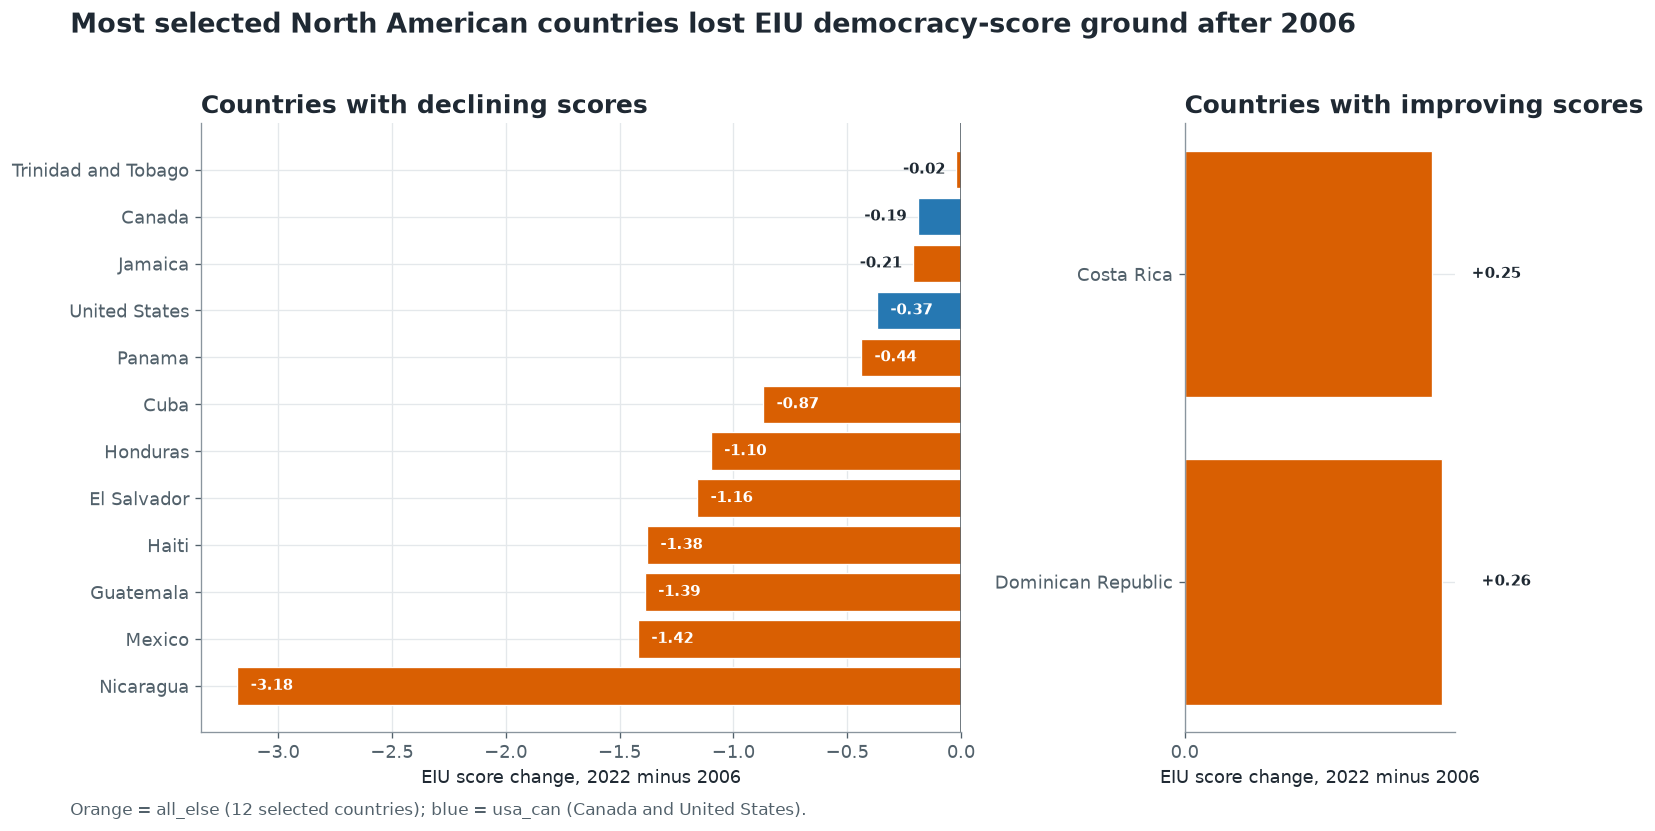

Saved: figures/don_north_america_score_change_2006_2022.png


In [15]:
plot_data = country_split.with_columns(
    pl.when(pl.col("group") == "all_else").then(pl.lit(ALL_ELSE)).otherwise(pl.lit(USA_CAN)).alias("color")
)
neg_plot = plot_data.filter(pl.col("delta_06_22") < 0).sort("delta_06_22")
pos_plot = plot_data.filter(pl.col("delta_06_22") > 0).sort("delta_06_22", descending=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), gridspec_kw={"width_ratios": [4.5, 1.6]})
for ax, frame, title in zip(axes, [neg_plot, pos_plot], ["Countries with declining scores", "Countries with improving scores"]):
    names = frame["Entity"].to_list()
    values = frame["delta_06_22"].to_list()
    colors = frame["color"].to_list()
    bars = ax.barh(names, values, color=colors, edgecolor="white", linewidth=0.8)
    ax.axvline(0, color="#59636a", linewidth=1)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlabel("EIU score change, 2022 minus 2006")
    ax.xaxis.set_major_locator(plt.MultipleLocator(0.5))
    for bar, value in zip(bars, values):
        y = bar.get_y() + bar.get_height() / 2
        if value <= -0.35:
            ax.text(value + 0.06, y, f"{value:+.2f}", va="center", ha="left", fontsize=9, color="white", fontweight="bold")
        elif value < 0:
            ax.text(value - 0.05, y, f"{value:+.2f}", va="center", ha="right", fontsize=9, color=INK, fontweight="bold")
        else:
            ax.text(value + 0.04, y, f"{value:+.2f}", va="center", ha="left", fontsize=9, color=INK, fontweight="bold")

fig.suptitle("Most selected North American countries lost EIU democracy-score ground after 2006", x=0.05, ha="left", y=1.02, fontsize=16, fontweight="bold")
fig.text(0.05, -0.01, "Orange = all_else (12 selected countries); blue = usa_can (Canada and United States).", color=MUTED, fontsize=10)
fig.tight_layout()
figure_path = FIGS / "don_north_america_score_change_2006_2022.png"
fig.savefig(figure_path, bbox_inches="tight", dpi=200)
plt.show()
print(f"Saved: {figure_path}")

## Interpretation and limits

The `all_else` countries’ mean endpoint change is more negative than the `usa_can` mean, and the difference is concentrated after 2014. The leave-one-country-out range shows that the average decline remains negative even when any one of the 12 countries is omitted. This does not show that geography, any policy, or an event caused the difference: the groups are deliberate geographic selections; scores are country-level EIU measures; and the panel has no 2007 or 2009 observations. The analysis describes score movement only and does not explain its causes.

In [19]:
all_else_summary = group_summary.filter(pl.col("group") == "all_else").row(0, named=True)
usa_can_summary = group_summary.filter(pl.col("group") == "usa_can").row(0, named=True)
print(
    f"Finding: all_else mean change = {all_else_summary['mean_delta_06_22']:.2f}; "
    f"usa_can mean change = {usa_can_summary['mean_delta_06_22']:.2f}.\n"
    f"Early (2006–2014): {all_else_summary['mean_delta_06_14']:.2f} vs {usa_can_summary['mean_delta_06_14']:.2f}; "
    f"late (2014–2022): {all_else_summary['mean_delta_14_22']:.2f} vs {usa_can_summary['mean_delta_14_22']:.2f}.\n"
    f"Sensitivity range after omitting one all_else country: {loo_min:.2f} to {loo_max:.2f}."
)

largest_negative = (
    country_split.filter(pl.col("delta_06_22") < 0)
    .sort("delta_06_22")
    .head(5)
    .select("Entity", "Code", "group", "delta_06_22")
)
print("\nFive countries with the largest negative endpoint deltas:")
print(largest_negative)

Finding: all_else mean change = -0.89; usa_can mean change = -0.28.
Early (2006–2014): -0.08 vs -0.05; late (2014–2022): -0.81 vs -0.23.
Sensitivity range after omitting one all_else country: -0.99 to -0.68.

Five countries with the largest negative endpoint deltas:
shape: (5, 4)
┌─────────────┬──────┬──────────┬─────────────┐
│ Entity      ┆ Code ┆ group    ┆ delta_06_22 │
│ ---         ┆ ---  ┆ ---      ┆ ---         │
│ str         ┆ str  ┆ str      ┆ f64         │
╞═════════════╪══════╪══════════╪═════════════╡
│ Nicaragua   ┆ NIC  ┆ all_else ┆ -3.18       │
│ Mexico      ┆ MEX  ┆ all_else ┆ -1.42       │
│ Guatemala   ┆ GTM  ┆ all_else ┆ -1.39       │
│ Haiti       ┆ HTI  ┆ all_else ┆ -1.38       │
│ El Salvador ┆ SLV  ┆ all_else ┆ -1.16       │
└─────────────┴──────┴──────────┴─────────────┘
